Description...

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# Function Form

In [ ]:
from pathlib import Path
from typing import Any, Dict, List, Tuple
import h5py
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# DEFAULT HARDWARE TOPOLOGY & CONFIGURATIONS
# ==============================================================================
DEFAULT_BAR_MAP = {i: (2 * i, 2 * i + 1) for i in range(12)}
DEFAULT_FREE_CHANNELS = list(range(24, 32))

DEFAULT_CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}
DEFAULT_CHANNEL_CONFIG.update({
    0: {"gain": 8, "bias": 104}, 1: {"gain": 8, "bias": 104},
    2: {"gain": 8, "bias": 110}, 3: {"gain": 8, "bias": 110},
    4: {"gain": 8, "bias": 112}, 5: {"gain": 8, "bias": 112},
    6: {"gain": 5, "bias": 102}, 7: {"gain": 1, "bias": 0},
    25: {"gain": 9, "bias": 140},
})


# ==============================================================================
# 1. DATA INGESTION & ELAPSED TIME
# ==============================================================================
def load_veto_data(file_path: Path, clock_tick_s: float = 10e-9) -> Tuple[np.ndarray, float]:
    """Loads charges and evaluates true elapsed run duration from timestamps."""
    with h5py.File(file_path, "r") as h5f:
        charges = h5f["charges"][:].astype(np.float32)
        timestamps = h5f["events"]["timestamp"][:]

    raw_dt = np.diff(timestamps)
    elapsed_time_s = float(np.sum(raw_dt[raw_dt >= 0]) * clock_tick_s)
    if elapsed_time_s <= 0:
        elapsed_time_s = 1.0

    return charges, elapsed_time_s


# ==============================================================================
# 2. ELECTRONIC NOISE LEARNING (FREE CHANNELS)
# ==============================================================================
def learn_electronic_noise(
    charges: np.ndarray,
    free_channels: List[int],
    config: Dict[int, Dict[str, int]],
    verbose: bool = True
) -> Tuple[Dict[str, Any], float]:
    """Calculates intrinsic electronic noise scaled per gain unit from open channels."""
    peds, sigmas, norm_sigmas = {}, {}, []

    for ch in free_channels:
        data = charges[:, ch]
        med = float(np.median(data))
        mad = float(np.median(np.abs(data - med)))
        sigma = 1.4826 * mad if mad > 0 else float(np.std(data))
        g = config[ch]["gain"]
        
        peds[ch] = med
        sigmas[ch] = sigma
        norm_sigmas.append(sigma / g)

    sigma_per_gain = float(np.median(norm_sigmas))

    if verbose:
        print("=" * 80)
        print("ELECTRONIC NOISE BENCHMARK (UNCONNECTED CHANNELS)")
        print("=" * 80)
        print(f"{'Channel':<10} | {'Gain':<6} | {'Pedestal (ADC)':<16} | {'Noise RMS (ADC)':<16} | {'Sigma / Gain':<15}")
        print("-" * 80)
        for ch in free_channels:
            print(f"Ch {ch:<7} | {config[ch]['gain']:<6} | {peds[ch]:<16.2f} | {sigmas[ch]:<16.2f} | {sigmas[ch]/config[ch]['gain']:<15.2f}")
        print("-" * 80)
        print(f"--> Median Electronic Floor: ±{sigma_per_gain * 10.0:.2f} ADC @ Gain 10 ({sigma_per_gain:.2f} ADC/Gain)\n")

    return {"pedestals": peds, "sigmas": sigmas}, sigma_per_gain


# ==============================================================================
# 3. BASELINES & GAIN-SCALED THRESHOLDS
# ==============================================================================
def compute_thresholds(
    charges: np.ndarray,
    config: Dict[int, Dict[str, int]],
    sigma_per_gain: float,
    ped_samples: int = 100_000
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Determines physical baselines and gain-scaled 5-sigma hit thresholds."""
    n_events, n_channels = charges.shape
    sample = charges[:ped_samples]
    
    med = np.median(sample, axis=0)
    mad = np.median(np.abs(sample - med), axis=0)
    measured_sigma = 1.4826 * mad

    gains = np.array([config[ch]["gain"] for ch in range(n_channels)], dtype=float)
    expected_sigma = sigma_per_gain * gains
    
    eff_sigma = np.clip(np.maximum(measured_sigma, expected_sigma), None, 25.0)
    min_cuts = 35.0 * (gains / 10.0)
    thresholds = med + np.maximum(5.0 * eff_sigma, min_cuts)

    return med, eff_sigma, thresholds


# ==============================================================================
# 4. COINCIDENCE SEARCH & TRIGGER RECONCILIATION
# ==============================================================================
def evaluate_coincidences(
    charges: np.ndarray,
    thresholds: np.ndarray,
    pedestals: np.ndarray,
    ped_rms: np.ndarray,
    bar_map: Dict[int, Tuple[int, int]],
    elapsed_time_s: float,
    saturation_adc: float = 3800,
    verbose: bool = True
) -> Dict[str, Any]:
    """Evaluates pairwise coincidence rates, bar saturation, and trigger composition."""
    n_events = len(charges)
    bar_stats = {}
    coinc_masks = []

    if verbose:
        print("=" * 118)
        print(f"{'Bar':<5} | {'SiPMs':<8} | {'Ped A (RMS)':<16} | {'Ped B (RMS)':<16} | {'Sat A %':<9} | {'Sat B %':<9} | {'Rate (Hz)':<10} | {'Status'}")
        print("=" * 118)

    for bar_id, (ch_a, ch_b) in bar_map.items():
        q_a, q_b = charges[:, ch_a], charges[:, ch_b]
        mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
        coinc_masks.append(mask)
        hits = int(np.count_nonzero(mask))
        rate_hz = hits / elapsed_time_s

        sat_a = (np.count_nonzero(q_a[mask] >= saturation_adc) / hits * 100.0) if hits else 0.0
        sat_b = (np.count_nonzero(q_b[mask] >= saturation_adc) / hits * 100.0) if hits else 0.0

        status = "SINGING! ⚠️" if rate_hz > 50 else ("DEAF / OFF" if rate_hz < 1.0 else "OK (Cosmic)")

        bar_stats[bar_id] = {
            "ch_a": ch_a, "ch_b": ch_b, "hits": hits, "rate": rate_hz,
            "sat_a": sat_a, "sat_b": sat_b, "mask": mask
        }

        if verbose:
            p_a = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
            p_b = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
            print(f"{bar_id:<5} | {ch_a:>2},{ch_b:<2}   | {p_a:<16} | {p_b:<16} | {sat_a:<8.2f}% | {sat_b:<8.2f}% | {rate_hz:<10.1f} | {status}")

    # Attribution Reconciliation
    coinc_matrix = np.column_stack(coinc_masks)
    bars_fired = np.sum(coinc_matrix, axis=1)
    reconciliation = {
        "n_zero": int(np.count_nonzero(bars_fired == 0)),
        "n_single": int(np.count_nonzero(bars_fired == 1)),
        "n_multi": int(np.count_nonzero(bars_fired >= 2)),
    }

    if verbose:
        print("=" * 118)
        print(f"Trigger Attribution: Single-Bar = {reconciliation['n_single']/n_events*100:.1f}% | "
              f"Multi-Bar = {reconciliation['n_multi']/n_events*100:.1f}% | "
              f"Ghost/Noise = {reconciliation['n_zero']/n_events*100:.1f}%\n")

    return {"bar_stats": bar_stats, "reconciliation": reconciliation}


# ==============================================================================
# 5. DIAGNOSTIC PLOTTING MODULES
# ==============================================================================
def plot_noise_channels(charges: np.ndarray, free_channels: List[int], noise_data: Dict[str, Any], config: Dict[int, Dict[str, int]]) -> None:
    """Diagnostic Plot 1: Noise profiles of unconnected channels."""
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
    for idx, ch in enumerate(free_channels):
        ax = axes.flatten()[idx]
        med, sig = noise_data["pedestals"][ch], noise_data["sigmas"][ch]
        ax.hist(charges[:, ch], bins=60, range=(med - 50, med + 50), color="mediumseagreen", alpha=0.7)
        ax.axvline(med, color="darkblue", linestyle="--", label=f"Ped ({med:.1f})")
        ax.axvline(med + 5 * sig, color="crimson", linestyle=":", label="+5σ")
        ax.set_title(f"Ch {ch} (G{config[ch]['gain']}) RMS: ±{sig:.2f}", fontsize=9, fontweight="bold")
        ax.legend(fontsize=7)
    plt.suptitle("Pure Electronic Baseline Noise (Free Channels)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plot_bar_spectra(charges: np.ndarray, bar_stats: Dict[int, Any], saturation_adc: float = 3800) -> None:
    """Diagnostic Plot 2: 12-bar charge overlay with weighted background scaling."""
    fig, axes = plt.subplots(3, 4, figsize=(18, 12), sharey=True)
    for b, ax in zip(bar_stats.keys(), axes.flatten()):
        ch_a, ch_b = bar_stats[b]["ch_a"], bar_stats[b]["ch_b"]
        mask = bar_stats[b]["mask"]
        q_a, q_b = charges[:, ch_a], charges[:, ch_b]

        x_max = min(max(np.percentile(q_a, 99.8), np.percentile(q_b, 99.8), 1200) * 1.2, 4150)
        bins = np.linspace(0, x_max, 100)

        # Scaled raw baseline
        sub = min(len(q_a), 20000)
        idx = np.random.choice(len(q_a), sub, replace=False)
        w = np.full(sub, len(q_a) / sub)
        ax.hist(q_a[idx], bins=bins, weights=w, color="skyblue", alpha=0.3, label=f"Raw A ({ch_a})")
        ax.hist(q_b[idx], bins=bins, weights=w, color="salmon", alpha=0.3, label=f"Raw B ({ch_b})")

        if np.any(mask):
            ax.hist(q_a[mask], bins=bins, histtype="step", color="royalblue", lw=1.4, label=f"Coinc A ({ch_a})")
            ax.hist(q_b[mask], bins=bins, histtype="step", color="crimson", lw=1.4, label=f"Coinc B ({ch_b})")

        ax.set_title(f"Bar {b} | {bar_stats[b]['rate']:.1f} Hz", fontsize=9, fontweight="bold")
        ax.set_yscale("log")
        ax.set_xlim(0, x_max)
        ax.legend(fontsize=6.5, loc="upper right")
    plt.suptitle("Active Bars: Charge Spectra Overlay", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plot_bar_correlations(charges: np.ndarray, bar_stats: Dict[int, Any], max_points: int = 2500) -> None:
    """Diagnostic Plot 3: 2D coincidence correlation scatter/density."""
    fig, axes = plt.subplots(3, 4, figsize=(16, 11), sharex=True, sharey=True)
    for b, ax in zip(bar_stats.keys(), axes.flatten()):
        ch_a, ch_b = bar_stats[b]["ch_a"], bar_stats[b]["ch_b"]
        mask = bar_stats[b]["mask"]
        hits = np.count_nonzero(mask)

        if hits > 5:
            indices = np.where(mask)[0]
            if len(indices) > max_points:
                indices = np.random.choice(indices, max_points, replace=False)
            ax.scatter(charges[indices, ch_a], charges[indices, ch_b], color="purple", s=3, alpha=0.35)
        else:
            ax.text(0.5, 0.5, "No Coinc Hits", ha="center", va="center", transform=ax.transAxes, color="gray")

        ax.set_title(f"Bar {b}: Ch {ch_a} vs Ch {ch_b}", fontsize=9, fontweight="bold")
        ax.set_xlim(0, 4150)
        ax.set_ylim(0, 4150)
    plt.suptitle("SiPM A vs SiPM B Coincidence Correlations", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


# ==============================================================================
# MASTER WORKFLOW ORCHESTRATOR
# ==============================================================================
def analyze_veto_run(
    file_path: str | Path,
    bar_map: Dict[int, Tuple[int, int]] = DEFAULT_BAR_MAP,
    free_channels: List[int] = DEFAULT_FREE_CHANNELS,
    channel_config: Dict[int, Dict[str, int]] = DEFAULT_CHANNEL_CONFIG,
    verbose: bool = True,
    show_noise_plot: bool = True,
    show_spectra_plot: bool = True,
    show_correlation_plot: bool = True,
) -> Dict[str, Any]:
    """Runs end-to-end characterization of a muon veto HDF5 run with togglable diagnostics."""
    file_path = Path(file_path)
    if not file_path.exists():
        raise FileNotFoundError(f"File not found: {file_path}")

    # 1. Ingest
    charges, elapsed_time_s = load_veto_data(file_path)
    if verbose:
        print(f"Loaded {len(charges):,} events ({elapsed_time_s:.2f} s | {len(charges)/elapsed_time_s:.1f} Hz total DAQ rate)")

    # 2. Electronic Noise Calibration
    noise_data, sigma_per_gain = learn_electronic_noise(charges, free_channels, channel_config, verbose=verbose)

    # 3. Baselines & Thresholds
    pedestals, ped_rms, thresholds = compute_thresholds(charges, channel_config, sigma_per_gain)

    # 4. Coincidences & Status
    results = evaluate_coincidences(
        charges, thresholds, pedestals, ped_rms, bar_map, elapsed_time_s, verbose=verbose
    )

    # 5. Diagnostic Plots
    if show_noise_plot:
        plot_noise_channels(charges, free_channels, noise_data, channel_config)
    if show_spectra_plot:
        plot_bar_spectra(charges, results["bar_stats"])
    if show_correlation_plot:
        plot_bar_correlations(charges, results["bar_stats"])

    return {
        "elapsed_time_s": elapsed_time_s,
        "pedestals": pedestals,
        "ped_rms": ped_rms,
        "thresholds": thresholds,
        "bar_stats": results["bar_stats"],
        "reconciliation": results["reconciliation"],
    }

In [ ]:
results = analyze_veto_run(
    "/lhome/ific/c/ccortesp/Data/Muon_Veto/module3/muons_20261102-114239.h5",
    verbose=True,
    show_noise_plot=False,         # Turn off noise plot
    show_spectra_plot=True,        # Show only 1D charge spectra
    show_correlation_plot=False    # Turn off 2D scatter
)

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/module3/muons_20261102-114239.h5
Loaded 15,104 events over 305.90 seconds.
Total DAQ Trigger Rate: 49.4 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Normalized Sigma/Gain
------------------------------------------------------------------------------
Ch 6       | 10     | 215.00           | 25.20            | 2.52                
Ch 7       | 10     | 203.00           | 53.37            | 5.34                
Ch 24      | 10     | 211.00           | 23.72            | 2.37                
Ch 25      | 10     | 198.00           | 25.20            | 2.52                
------------------------------------------------------------------------------
--> Median Sigma @ Gain 10: ±25.20 ADC counts
--> Normalized Electronic Sigma: 2.52 ADC counts / Gain

Mean of free_pedestals: 206.75
Mean of free_sigmas: 31.88
Bar   | SiPM A,B   | Ped A (RMS)      | Ped B (RMS)      | Threshol

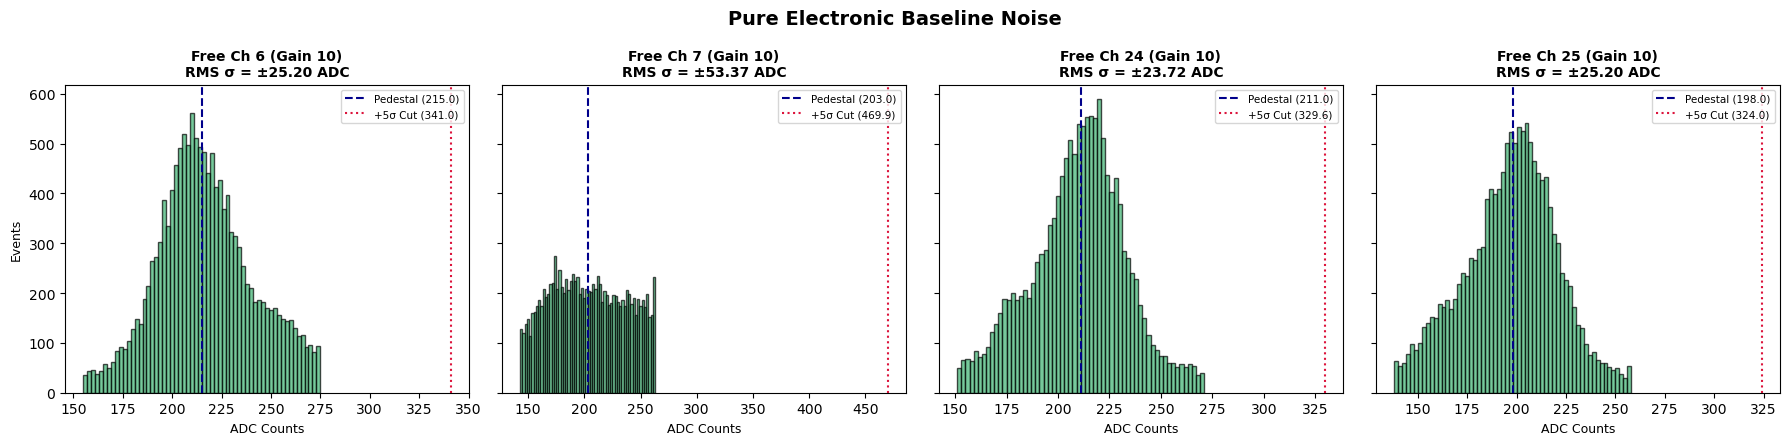

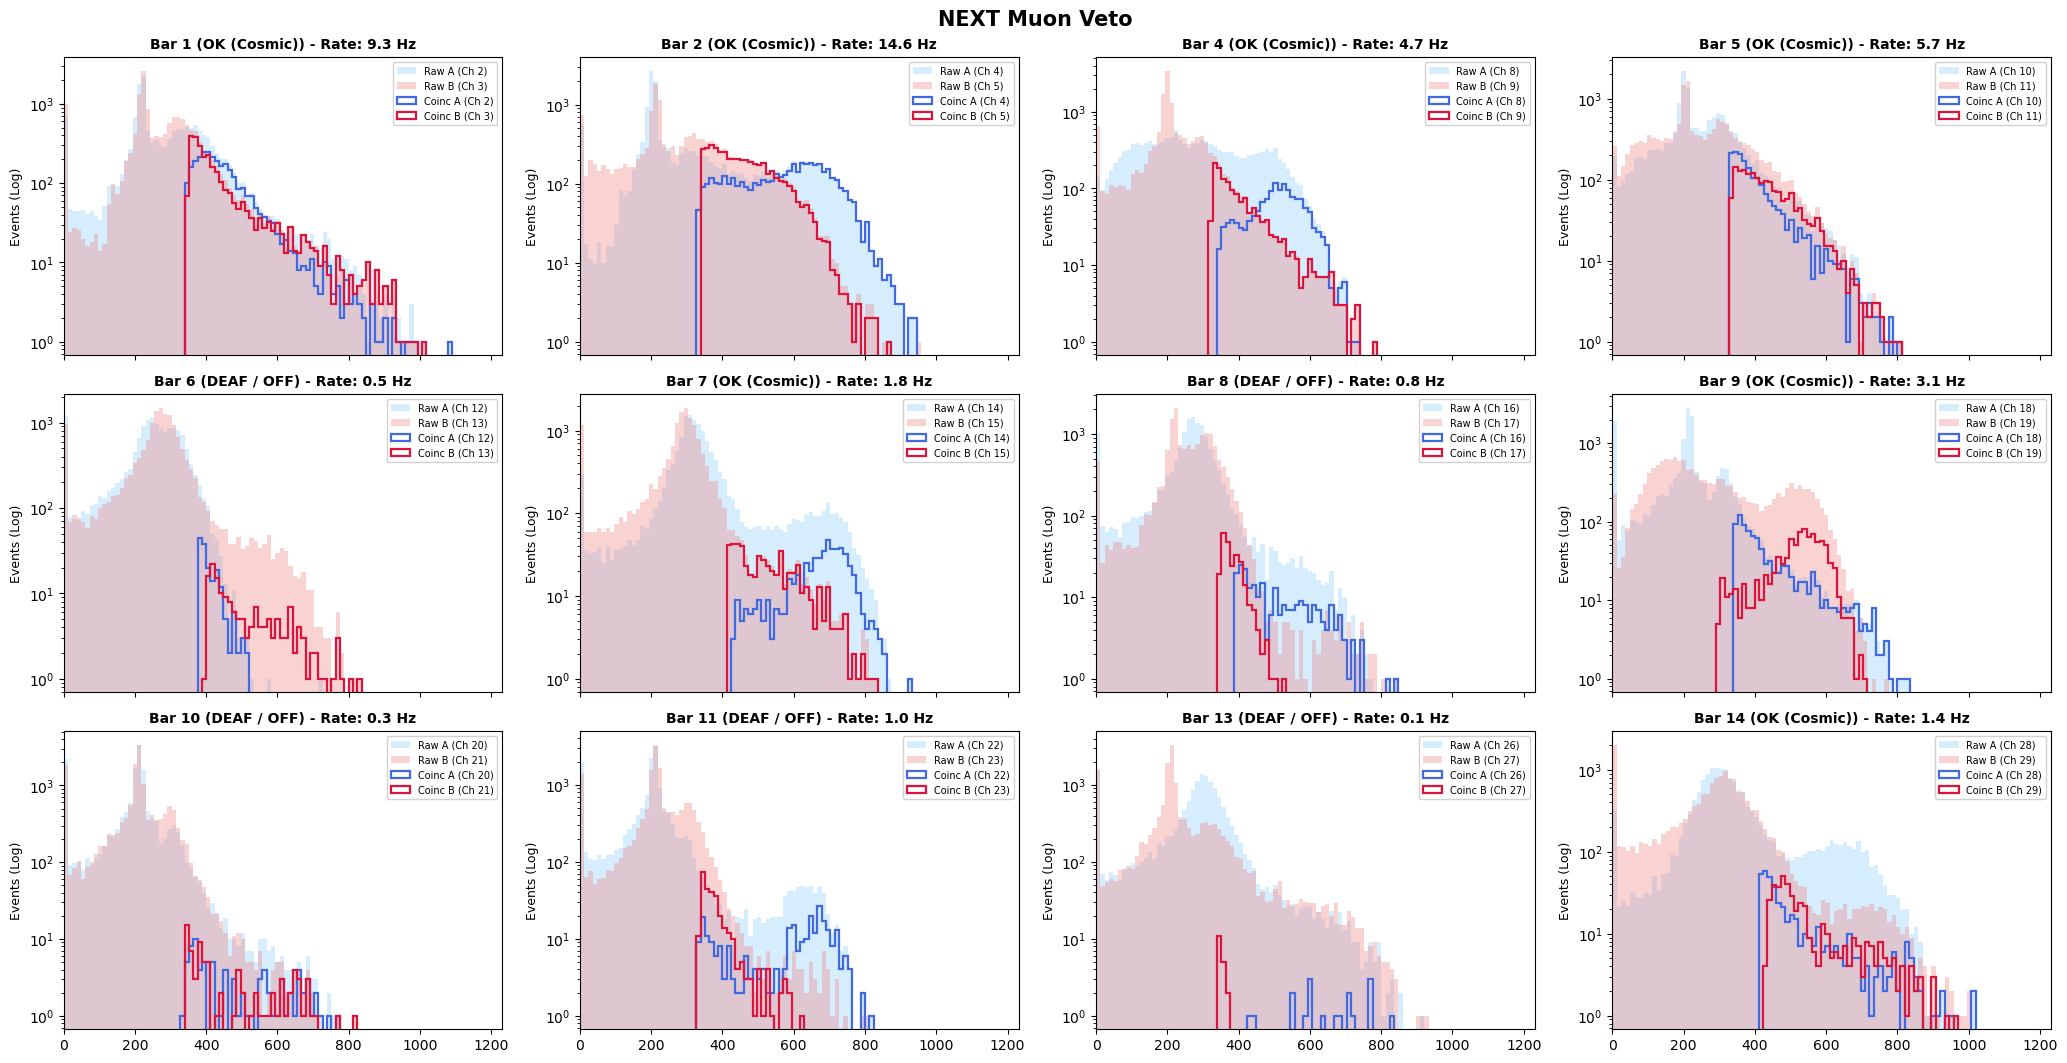

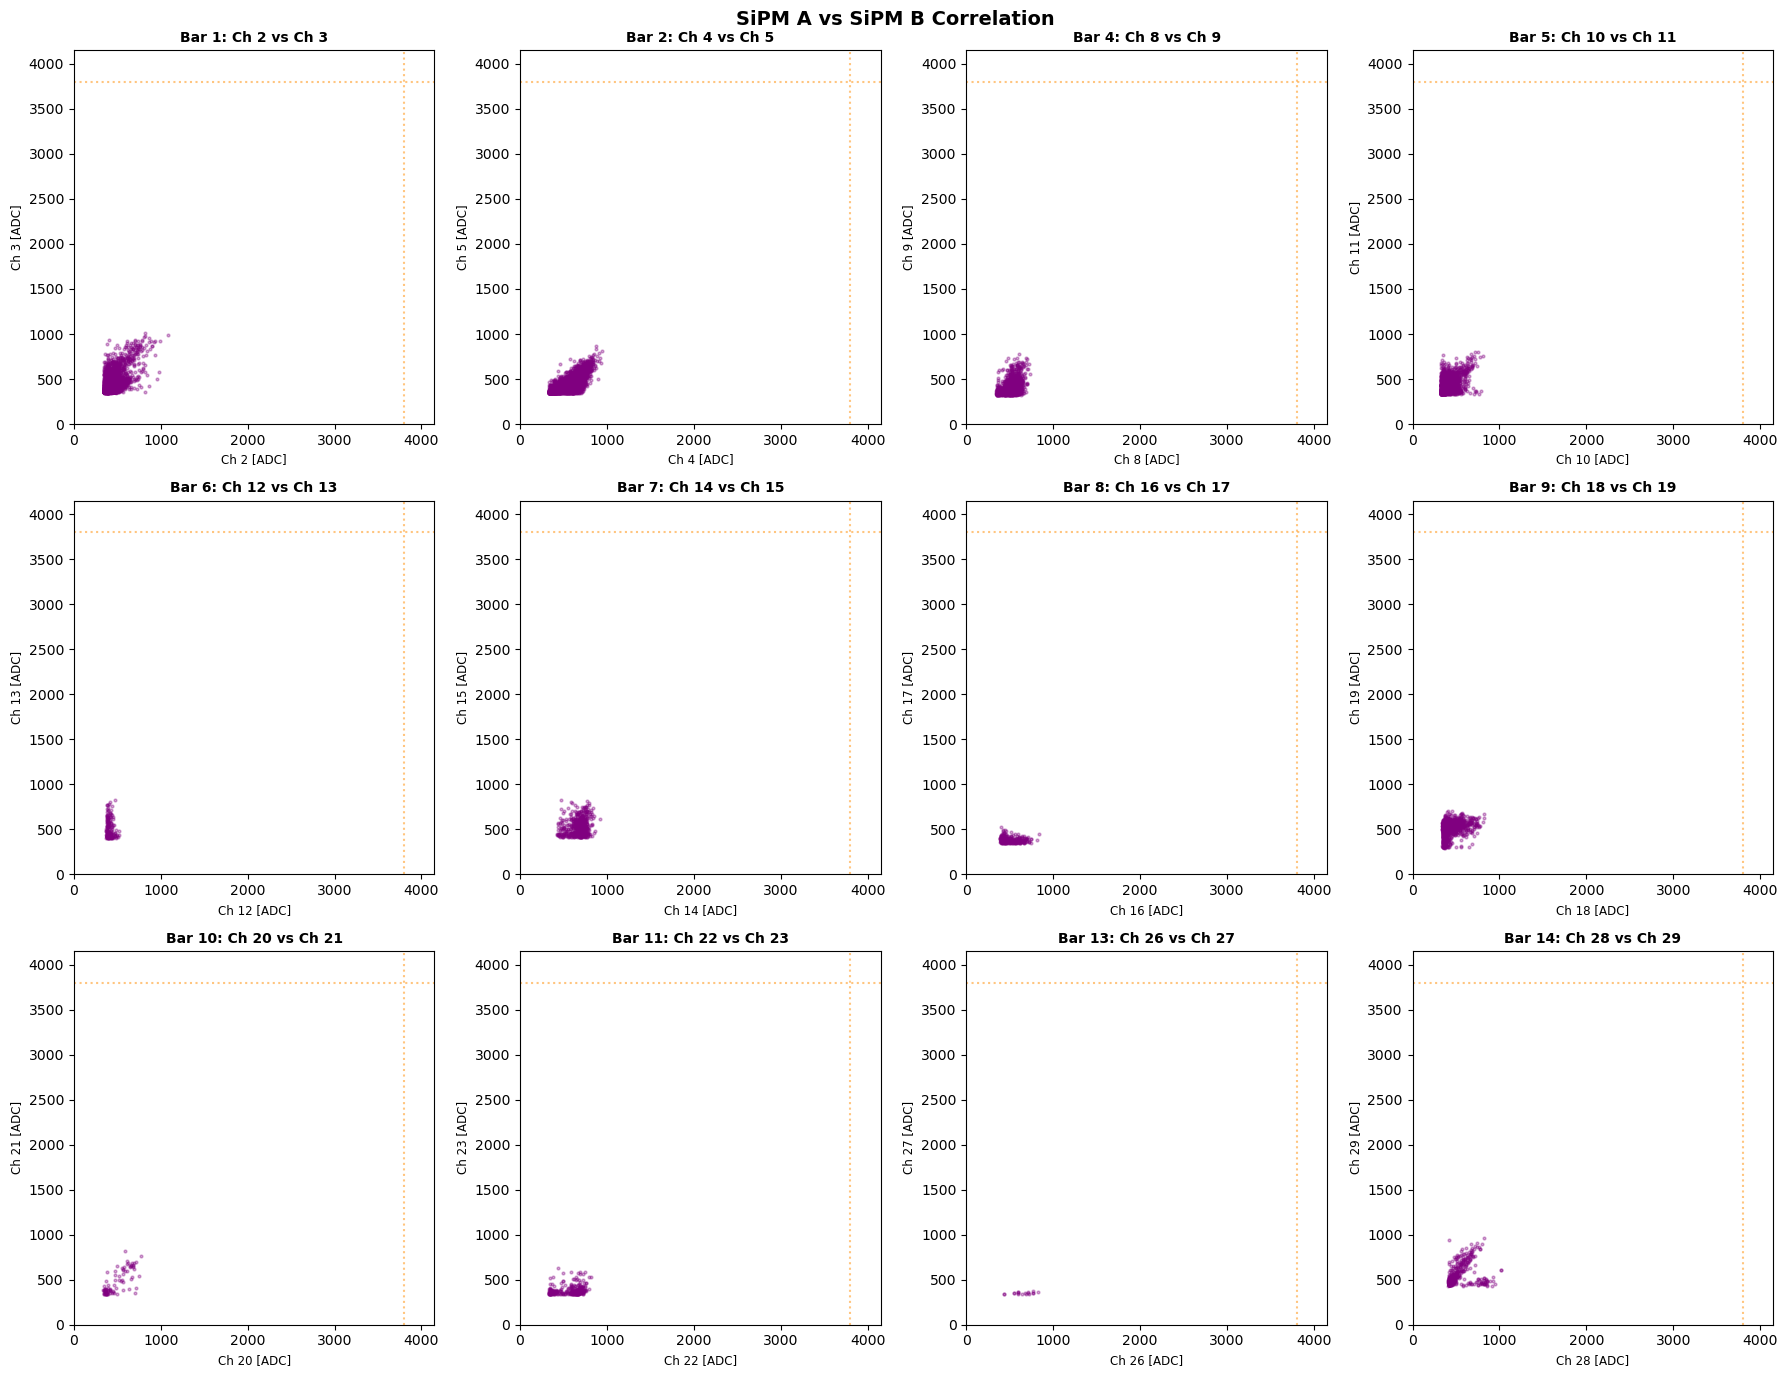

In [22]:
# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/module3/muons_20261102-114239.h5"

BAR_MAP = {
    # 0:  (0, 1),
    1:  (2, 3),
    2:  (4, 5),
    # 3:  (6, 7),
    4:  (8, 9),
    5:  (10, 11),
    6:  (12, 13),
    7:  (14, 15),
    8:  (16, 17),
    9:  (18, 19),
    10: (20, 21),
    11: (22, 23),
    # 12: (24, 25),
    13: (26, 27),
    14: (28, 29),
    # 15: (30, 31)
}

# Unconnected / Free channels used to characterize pure electronic noise
FREE_CHANNELS = [6, 7, 24, 25]

# Exact hardware configuration from your GUI
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}

SATURATION_ADC = 3800

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH}")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff  = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
total_daq_rate = n_events / elapsed_time_s
print(f"Total DAQ Trigger Rate: {total_daq_rate:.1f} Hz\n")

# ==============================================================================
# 1. PURE ELECTRONIC NOISE CHARACTERIZATION
# ==============================================================================
print("=" * 78)
print("ELECTRONIC NOISE FROM UNCONNECTED CHANNELS")
print("=" * 78)
print(f"{'Channel':<10} | {'Gain':<6} | {'Pedestal (ADC)':<16} | {'Noise RMS (ADC)':<16} | {'Normalized Sigma/Gain':<20}")
print("-" * 78)

free_pedestals = {}
free_sigmas = {}
norm_sigmas = []

for ch in FREE_CHANNELS:
    ch_data = charges[:, ch]
    med = np.median(ch_data)
    mad = np.median(np.abs(ch_data - med))
    sigma = 1.4826 * mad
    if sigma < 1.0:
        sigma = np.std(ch_data)
    
    g = CHANNEL_CONFIG[ch]['gain']
    norm_s = sigma / g
    norm_sigmas.append(norm_s)
    
    free_pedestals[ch] = med
    free_sigmas[ch]    = sigma
    print(f"Ch {ch:<7} | {g:<6} | {med:<16.2f} | {sigma:<16.2f} | {norm_s:<20.2f}")

# Characteristic electronic noise per unit gain
sigma_per_gain = float(np.median(norm_sigmas))
reference_sigma_g10 = sigma_per_gain * 10.0
print("-" * 78)
print(f"--> Median Sigma @ Gain 10: ±{reference_sigma_g10:.2f} ADC counts")
print(f"--> Normalized Electronic Sigma: {sigma_per_gain:.2f} ADC counts / Gain")
print("=" * 78 + "\n")

# ==============================================================================
# 2. BASELINE & GAIN-SCALED THRESHOLD DETERMINATION (Active Channels)
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

# Calculate the mean of free_pedestals and free_sigmas
mean_free_pedestals = np.mean(list(free_pedestals.values()))
mean_free_sigmas = np.mean(list(free_sigmas.values()))
lim_d = mean_free_pedestals - 5 * mean_free_sigmas
lim_u = mean_free_pedestals + 5 * mean_free_sigmas

print(f"Mean of free_pedestals: {mean_free_pedestals:.2f}")
print(f"Mean of free_sigmas: {mean_free_sigmas:.2f}")

for ch in range(n_channels):
    ch_data = charges[:, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(lim_d, lim_u))
    mode_ped = bin_edges[np.argmax(counts)]
        
    pedestals[ch] = mode_ped
    
    # Gain-scaled physical electronic threshold:
    ch_gain = CHANNEL_CONFIG[ch]['gain']
    ch_expected_elec_sigma = sigma_per_gain * ch_gain
    
    # Channel intrinsic spread (including residual dark counts)
    mad = np.median(np.abs(ch_data - mode_ped))
    ch_meas_sigma = 1.4826 * mad
    
    # Use the larger of measured or pure electronic noise (capped safely)
    eff_sigma = min(max(ch_meas_sigma, ch_expected_elec_sigma), 25.0)
    ped_rms[ch] = eff_sigma
    
    # Threshold = Pedestal + 5.0 * sigma, scaled with preamp gain
    min_cut = 35.0 * (ch_gain / 10.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * eff_sigma, min_cut)

# ==============================================================================
# 3. COINCIDENCE SEARCH & INDIVIDUAL METRICS
# ==============================================================================
bar_stats = {}
bar_masks = []

print("=" * 126)
print(f"{'Bar':<5} | {'SiPM A,B':<10} | {'Ped A (RMS)':<16} | {'Ped B (RMS)':<16} | {'Threshold A':<9} | {'Threshold B':<9} | {'Sat A %':<9} | {'Sat B %':<9} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Status':<12}")
print("=" * 126)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    bar_masks.append(coincidence_mask)
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'thres_a': thresholds[ch_a], 'thres_b': thresholds[ch_b],
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<16} | {ped_b_str:<16} | {thresholds[ch_a]:<2.2f}  | {thresholds[ch_b]:<2.2f} |{sat_a_pct:<8.2f}% | {sat_b_pct:<8.2f}% | {n_hits:<11,d} | {rate_hz:<10.1f} | {status:<12}")

print("=" * 126 + "\n")

# ==============================================================================
# 4. DAQ TRIGGER ATTRIBUTION & RATE RECONCILIATION
# ==============================================================================
coinc_matrix = np.column_stack(bar_masks)  # Shape: (N_events, N_bars)
bars_fired_per_event = np.sum(coinc_matrix, axis=1)

n_zero_bars = int(np.sum(bars_fired_per_event == 0))
n_single_bar = int(np.sum(bars_fired_per_event == 1))
n_multi_bars = int(np.sum(bars_fired_per_event >= 2))
sum_bar_hits = int(np.sum([bar_stats[b]['hits'] for b in BAR_MAP]))

print("=" * 65)
print("           DAQ TRIGGER ATTRIBUTION RECONCILIATION")
print("=" * 65)
print(f"Total DAQ Triggers Recorded:      {n_events:>10,d}  ({total_daq_rate:.1f} Hz)")
print(f"Sum of Hits across all Bars:      {sum_bar_hits:>10,d}  ({sum_bar_hits/elapsed_time_s:.1f} Hz)")
print("-" * 65)
print(f"  * Events with EXACTLY 1 Bar:    {n_single_bar:>10,d}  ({n_single_bar/n_events*100.1:.1f}%)")
print(f"  * Events with >= 2 Bars:        {n_multi_bars:>10,d}  ({n_multi_bars/n_events*100.1:.1f}%)")
print(f"  * Events with 0 Bars:           {n_zero_bars:>10,d}  ({n_zero_bars/n_events*100.1:.1f}%)")
print("=" * 65)
if n_zero_bars > 0:
    print(f"[!] Notice: {n_zero_bars:,} triggers ({n_zero_bars/elapsed_time_s:.1f} Hz) were DAQ noise / ghost triggers")
    print("    where none of the active bars satisfied the coincidence cut.")
print("\n")

# ==============================================================================
# DYNAMIC GRID CALCULATION
# ==============================================================================
n_bars = len(BAR_MAP)
n_cols = 4 if n_bars > 9 else 3
n_rows = int(np.ceil(n_bars / n_cols))

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')



# ==============================================================================
# PLOT 1: PURE ELECTRONIC NOISE OF UNCONNECTED CHANNELS
# ==============================================================================

free_rows = (len(FREE_CHANNELS) + 3) // 4  # Calculate rows dynamically based on FREE_CHANNELS
fig_f, axes_f = plt.subplots(free_rows, 4, figsize=(18, 4.5 * free_rows), sharey=True)
axes_f = axes_f.flatten()

for idx, ch in enumerate(FREE_CHANNELS):
    ax = axes_f[idx]
    ch_data = charges[:, ch]
    med = free_pedestals[ch]
    sig = free_sigmas[ch]
    g = CHANNEL_CONFIG[ch]['gain']
    
    ax.hist(ch_data, bins=60, range=(med - 60, med + 60), color='mediumseagreen', alpha=0.7, edgecolor='black')
    ax.axvline(med, color='darkblue', linestyle='--', label=f'Pedestal ({med:.1f})')
    ax.axvline(med + 5 * sig, color='crimson', linestyle=':', label=f'+5σ Cut ({med + 5*sig:.1f})')
    
    ax.set_title(f"Free Ch {ch} (Gain {g})\nRMS σ = ±{sig:.2f} ADC", fontsize=10, fontweight='bold')
    ax.set_xlabel("ADC Counts", fontsize=9)
    if idx % 4 == 0:
        ax.set_ylabel("Events", fontsize=9)
    ax.legend(fontsize=7.5, loc='upper right')

plt.suptitle("Pure Electronic Baseline Noise", fontsize=14, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_pure_electronic_noise.png", dpi=200)
print("[+] Saved: veto_pure_electronic_noise.png")

# ==============================================================================
# PLOT 2: ACTIVE 12 BARS DUAL BACKGROUNDS (PROPERLY SCALED)
# ==============================================================================
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.2 * n_cols, 3.6 * n_rows), sharex=True)
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    # Dynamic x-axis
    if np.sum(coinc_mask) > 10:
        max_seen = max(np.percentile(q_a[coinc_mask], 99.5), np.percentile(q_b[coinc_mask], 99.5))
        x_limit = min(max(max_seen * 1.3, 1200), 4150)
    else:
        max_raw = max(np.percentile(q_a, 99.5), np.percentile(q_b, 99.5))
        x_limit = min(max(max_raw * 1.3, 1000), 4150)
        
    bins = np.linspace(0, x_limit, 100)
    
    # Subsampled raw backgrounds WITH WEIGHTS to match full dataset scale!
    sub_size = min(len(q_a), 25000)
    sub_idx = np.random.choice(len(q_a), sub_size, replace=False)
    weights = np.full(sub_size, len(q_a) / sub_size)
    
    ax.hist(q_a[sub_idx], bins=bins, weights=weights, color='lightskyblue', alpha=0.35, label=f'Raw A (Ch {ch_a})')
    ax.hist(q_b[sub_idx], bins=bins, weights=weights, color='lightcoral', alpha=0.35, label=f'Raw B (Ch {ch_b})')
    
    # Coincidence signals
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=bins, color='royalblue', 
                histtype='step', linewidth=1.6, label=f'Coinc A (Ch {ch_a})')
        ax.hist(q_b[coinc_mask], bins=bins, color='crimson', 
                histtype='step', linewidth=1.6, label=f'Coinc B (Ch {ch_b})')
        
    if x_limit >= 3800:
        ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7)
        
    ax.set_title(f"Bar {bar_id} ({bar_stats[bar_id]['status']}) - Rate: {bar_stats[bar_id]['rate']:.1f} Hz", fontsize=10, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, x_limit)
    ax.legend(fontsize=7, loc='upper right', framealpha=0.9)
    
    if b >= 8:
        ax.set_xlabel("Charge [ADC counts]", fontsize=9)
    if b % 4 == 0:
        ax.set_ylabel("Events (Log)", fontsize=9)

plt.suptitle("NEXT Muon Veto", fontsize=15, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_12bars_gain_corrected.png", dpi=200)
print("[+] Saved: veto_12bars_gain_corrected.png")

# ==============================================================================
# PLOT 3: 2D CORRELATION PLOTS (FULL RANGE 0 TO 4150 ADC)
# ==============================================================================
fig, axes = plt.subplots(3, 4, figsize=(18, 14))
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    if np.sum(coinc_mask) > 5:
        idx = np.where(coinc_mask)[0]
        if len(idx) > 3000:
            idx = np.random.choice(idx, 3000, replace=False)
        ax.scatter(q_a[idx], q_b[idx], color='purple', s=4, alpha=0.35)
    else:
        ax.text(0.5, 0.5, 'No Coinc Hits', ha='center', va='center', transform=ax.transAxes, color='gray')
        
    ax.axhline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.set_title(f"Bar {bar_id}: Ch {ch_a} vs Ch {ch_b}", fontsize=10, fontweight='bold')
    ax.set_xlim(0, 4150)
    ax.set_ylim(0, 4150)
    ax.set_xlabel(f"Ch {ch_a} [ADC]", fontsize=8.5)
    ax.set_ylabel(f"Ch {ch_b} [ADC]", fontsize=8.5)

plt.suptitle("SiPM A vs SiPM B Correlation", fontsize=14, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_sipm_correlations_full.png", dpi=200)
print("[+] Saved: veto_sipm_correlations_full.png")

print("\nDone! All diagnostic plots and rate reconciliations generated.")

-----

## Try 2

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/module3/muons_20261102-145736.h5
Loaded 14,506 events over 397.00 seconds.
Total DAQ Trigger Rate: 36.5 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Normalized Sigma/Gain
------------------------------------------------------------------------------
Ch 6       | 10     | 222.00           | 34.10            | 3.41                
Ch 7       | 10     | 222.00           | 91.92            | 9.19                
Ch 24      | 10     | 209.00           | 32.62            | 3.26                
Ch 25      | 10     | 197.00           | 34.10            | 3.41                
------------------------------------------------------------------------------
--> Median Sigma @ Gain 10: ±34.10 ADC counts
--> Normalized Electronic Sigma: 3.41 ADC counts / Gain

Mean of free_pedestals: 212.50
Mean of free_sigmas: 32.62
Bar   | SiPM A,B   | Ped A (RMS)      | Ped B (RMS)      | Threshol

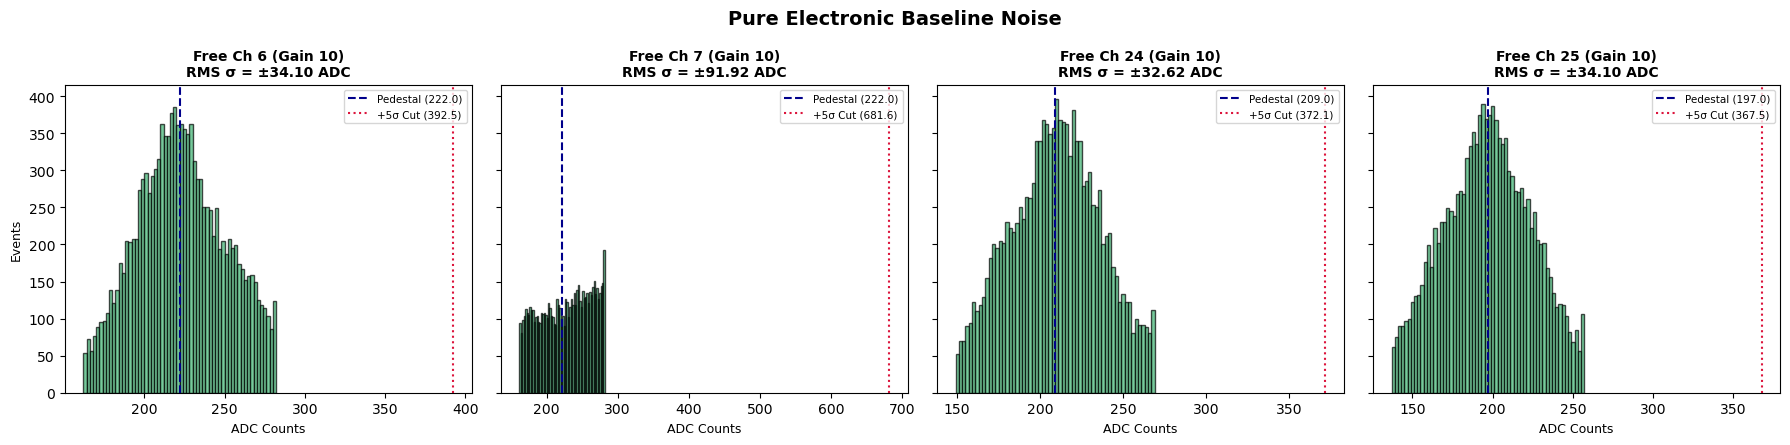

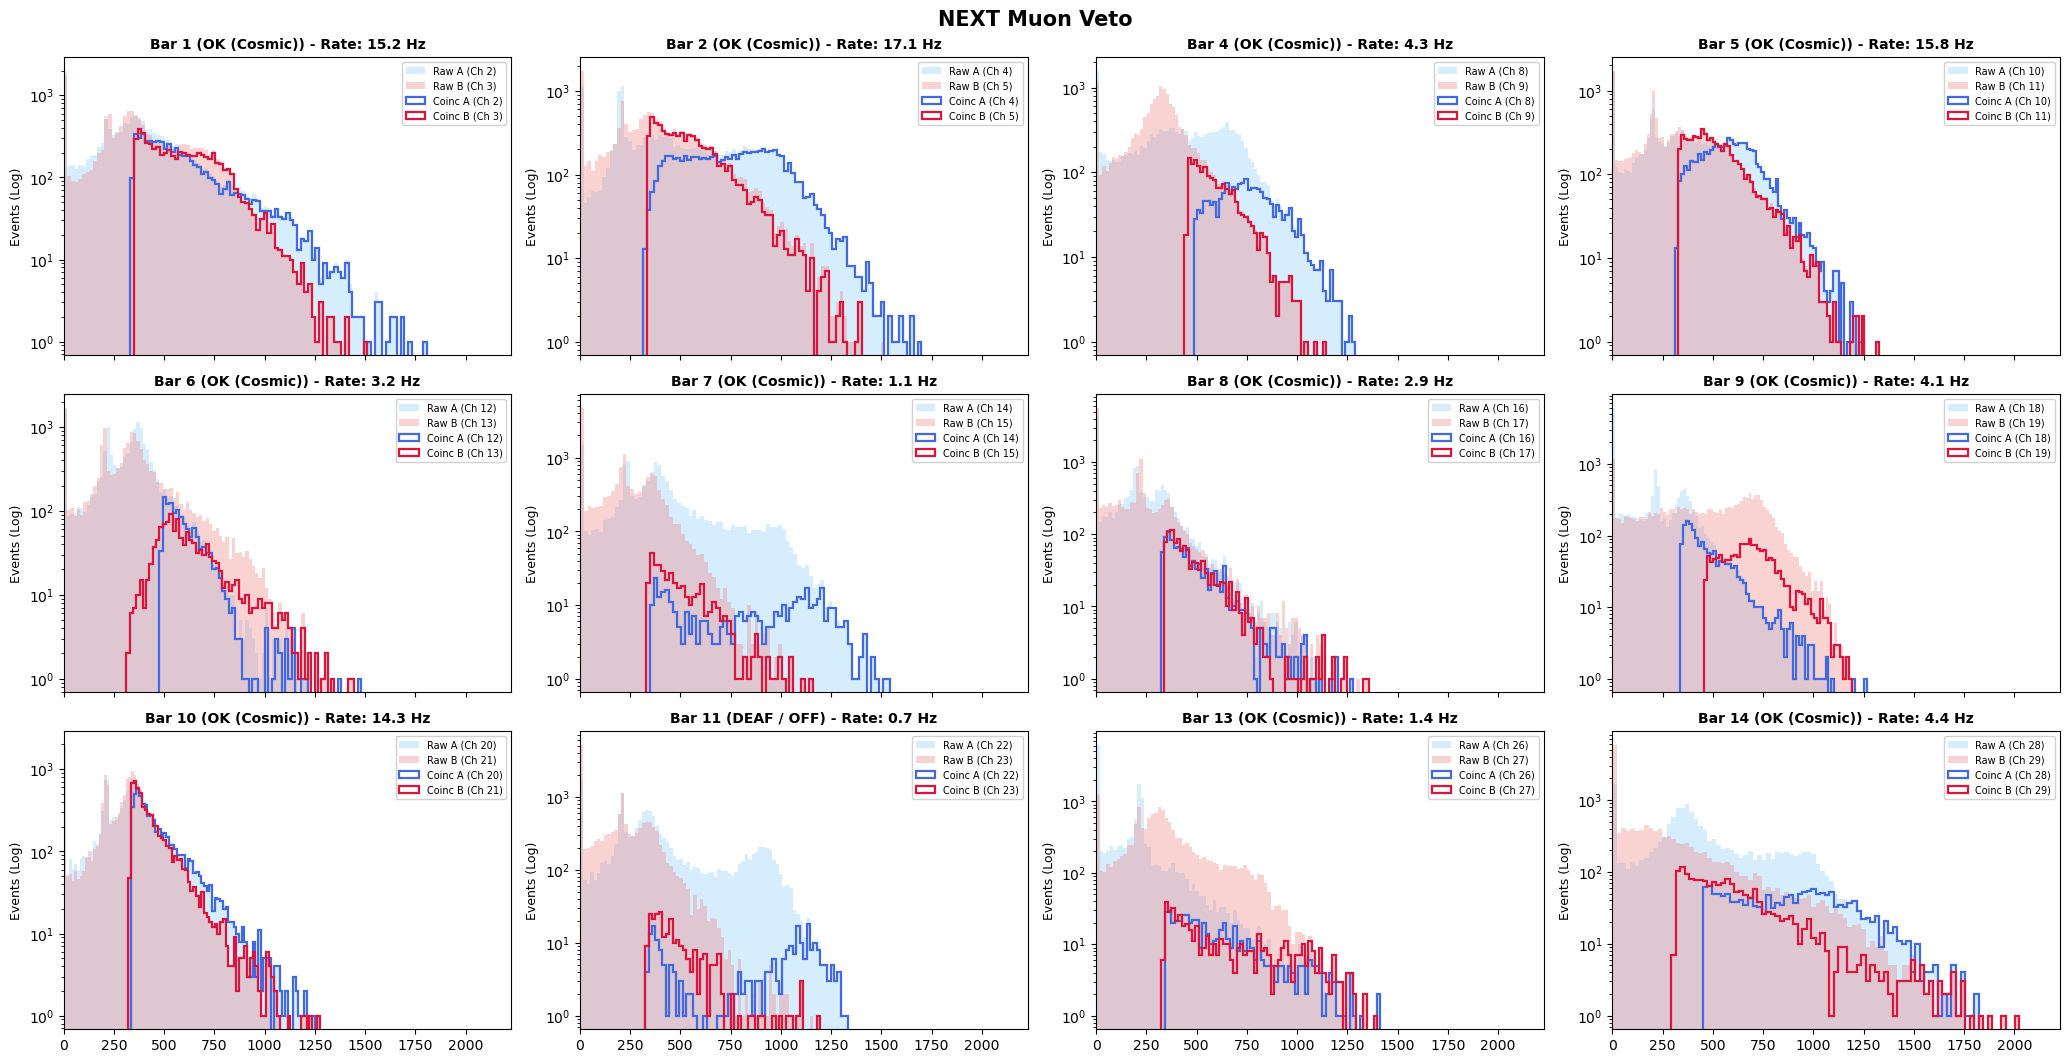

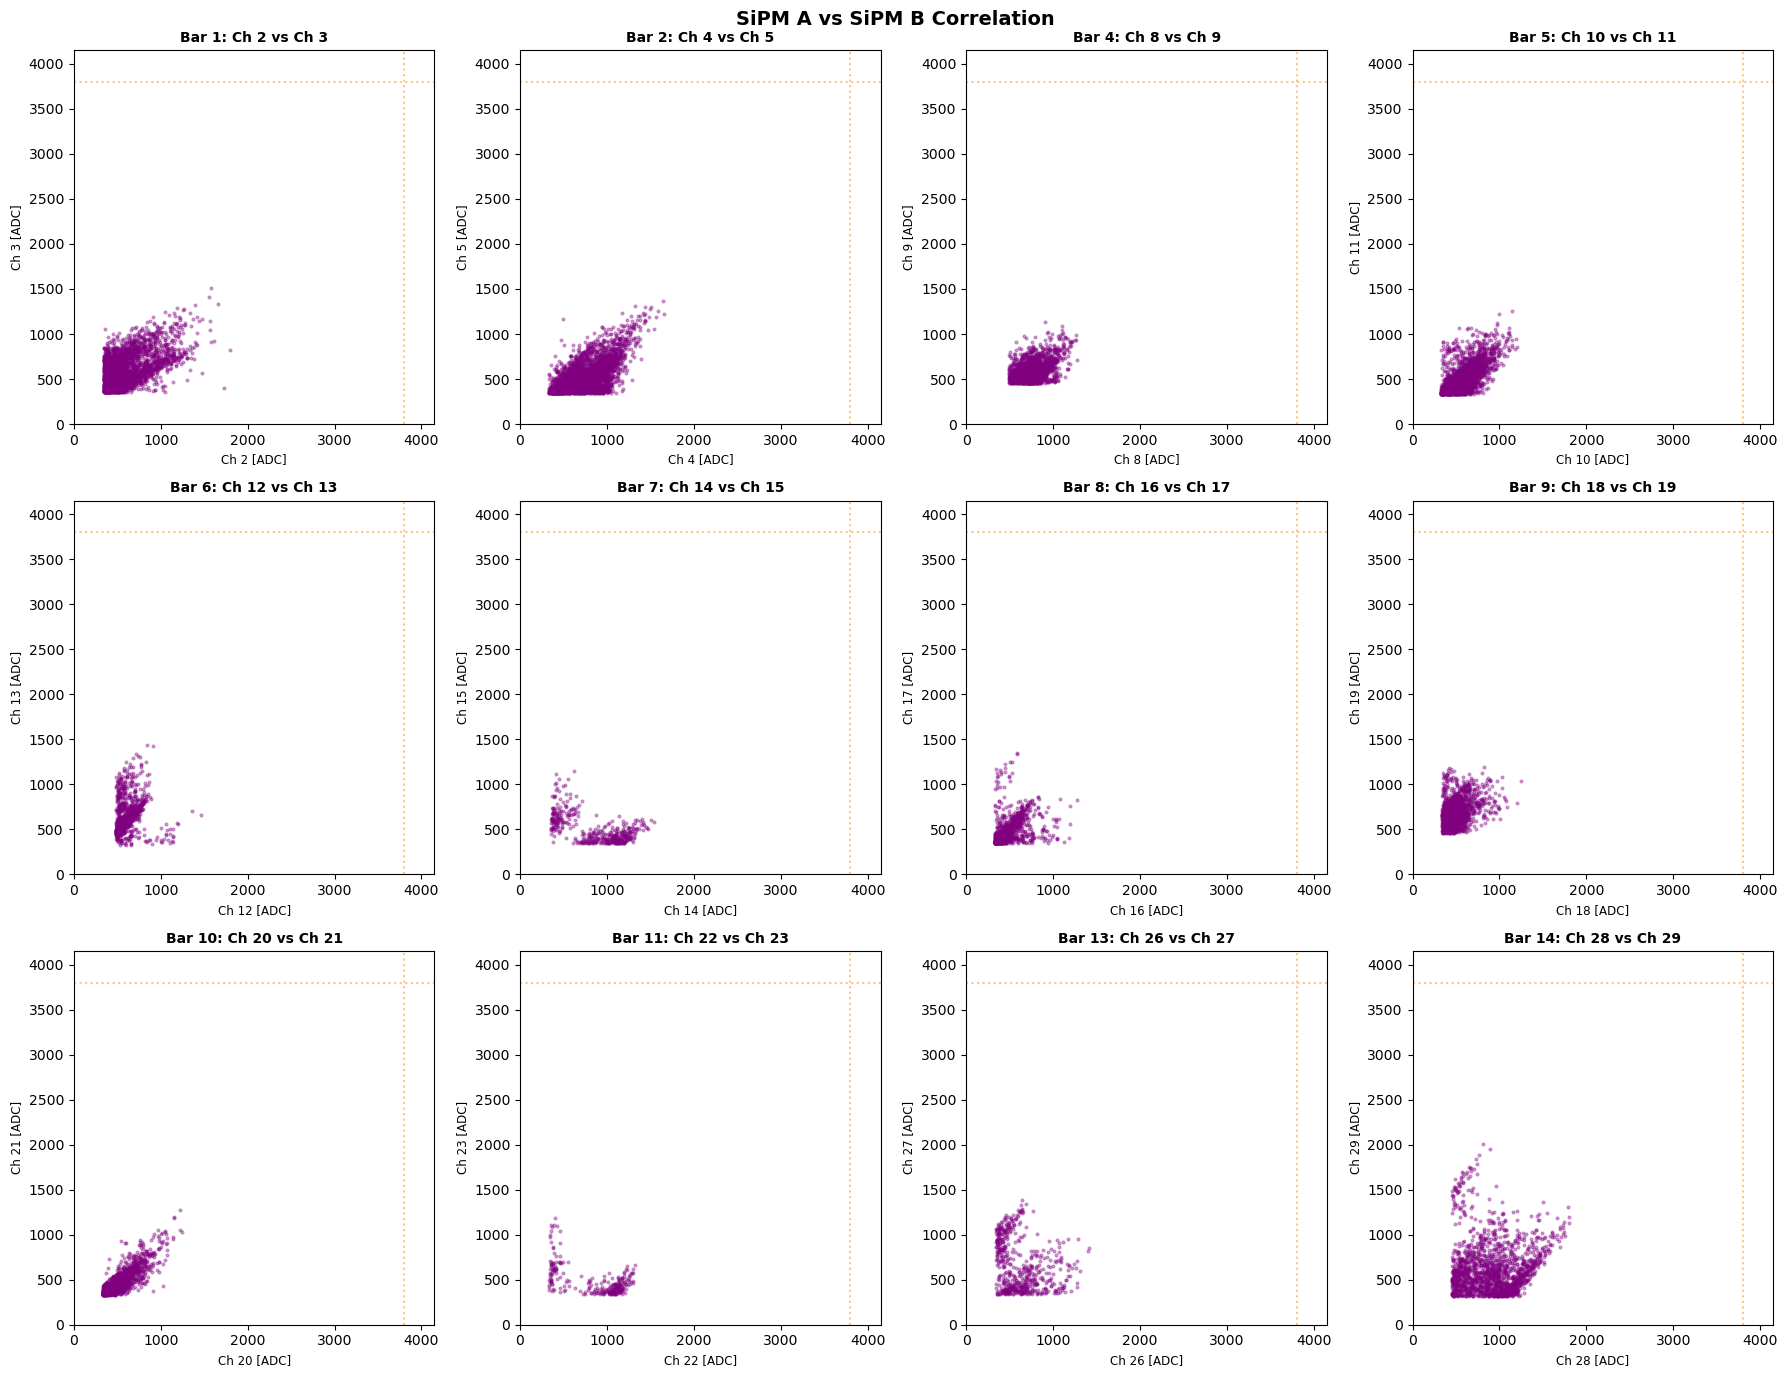

In [24]:
# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/module3/muons_20261102-145736.h5"

BAR_MAP = {
    # 0:  (0, 1),
    1:  (2, 3),
    2:  (4, 5),
    # 3:  (6, 7),
    4:  (8, 9),
    5:  (10, 11),
    6:  (12, 13),
    7:  (14, 15),
    8:  (16, 17),
    9:  (18, 19),
    10: (20, 21),
    11: (22, 23),
    # 12: (24, 25),
    13: (26, 27),
    14: (28, 29),
    # 15: (30, 31)
}

# Unconnected / Free channels used to characterize pure electronic noise
FREE_CHANNELS = [6, 7, 24, 25]

# Exact hardware configuration from your GUI
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}

SATURATION_ADC = 3800

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH}")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff  = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
total_daq_rate = n_events / elapsed_time_s
print(f"Total DAQ Trigger Rate: {total_daq_rate:.1f} Hz\n")

# ==============================================================================
# 1. PURE ELECTRONIC NOISE CHARACTERIZATION
# ==============================================================================
print("=" * 78)
print("ELECTRONIC NOISE FROM UNCONNECTED CHANNELS")
print("=" * 78)
print(f"{'Channel':<10} | {'Gain':<6} | {'Pedestal (ADC)':<16} | {'Noise RMS (ADC)':<16} | {'Normalized Sigma/Gain':<20}")
print("-" * 78)

free_pedestals = {}
free_sigmas = {}
norm_sigmas = []

for ch in FREE_CHANNELS:
    ch_data = charges[:, ch]
    med = np.median(ch_data)
    mad = np.median(np.abs(ch_data - med))
    sigma = 1.4826 * mad
    if sigma < 1.0:
        sigma = np.std(ch_data)
    
    g = CHANNEL_CONFIG[ch]['gain']
    norm_s = sigma / g
    norm_sigmas.append(norm_s)
    
    free_pedestals[ch] = med
    free_sigmas[ch]    = sigma
    print(f"Ch {ch:<7} | {g:<6} | {med:<16.2f} | {sigma:<16.2f} | {norm_s:<20.2f}")

# Characteristic electronic noise per unit gain
sigma_per_gain = float(np.median(norm_sigmas))
reference_sigma_g10 = sigma_per_gain * 10.0
print("-" * 78)
print(f"--> Median Sigma @ Gain 10: ±{reference_sigma_g10:.2f} ADC counts")
print(f"--> Normalized Electronic Sigma: {sigma_per_gain:.2f} ADC counts / Gain")
print("=" * 78 + "\n")

# ==============================================================================
# 2. BASELINE & GAIN-SCALED THRESHOLD DETERMINATION (Active Channels)
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

# Calculate the mean of free_pedestals and free_sigmas
mean_free_pedestals = np.mean(list(free_pedestals.values()))
mean_free_sigmas = np.min(list(free_sigmas.values()))
lim_d = mean_free_pedestals - 5 * mean_free_sigmas
lim_u = mean_free_pedestals + 5 * mean_free_sigmas

print(f"Mean of free_pedestals: {mean_free_pedestals:.2f}")
print(f"Mean of free_sigmas: {mean_free_sigmas:.2f}")

for ch in range(n_channels):
    ch_data = charges[:, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(lim_d, lim_u))
    mode_ped = bin_edges[np.argmax(counts)]
        
    pedestals[ch] = mode_ped
    
    # Gain-scaled physical electronic threshold:
    ch_gain = CHANNEL_CONFIG[ch]['gain']
    ch_expected_elec_sigma = sigma_per_gain * ch_gain
    
    # Channel intrinsic spread (including residual dark counts)
    mad = np.median(np.abs(ch_data - mode_ped))
    ch_meas_sigma = 1.4826 * mad
    
    # Use the larger of measured or pure electronic noise (capped safely)
    eff_sigma = min(max(ch_meas_sigma, ch_expected_elec_sigma), 25.0)
    ped_rms[ch] = eff_sigma
    
    # Threshold = Pedestal + 5.0 * sigma, scaled with preamp gain
    min_cut = 35.0 * (ch_gain / 10.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * eff_sigma, min_cut)

# ==============================================================================
# 3. COINCIDENCE SEARCH & INDIVIDUAL METRICS
# ==============================================================================
bar_stats = {}
bar_masks = []

print("=" * 126)
print(f"{'Bar':<5} | {'SiPM A,B':<10} | {'Ped A (RMS)':<16} | {'Ped B (RMS)':<16} | {'Threshold A':<9} | {'Threshold B':<9} | {'Sat A %':<9} | {'Sat B %':<9} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Status':<12}")
print("=" * 126)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    bar_masks.append(coincidence_mask)
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'thres_a': thresholds[ch_a], 'thres_b': thresholds[ch_b],
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<16} | {ped_b_str:<16} | {thresholds[ch_a]:<2.2f}  | {thresholds[ch_b]:<2.2f} |{sat_a_pct:<8.2f}% | {sat_b_pct:<8.2f}% | {n_hits:<11,d} | {rate_hz:<10.1f} | {status:<12}")

print("=" * 126 + "\n")

# ==============================================================================
# 4. DAQ TRIGGER ATTRIBUTION & RATE RECONCILIATION
# ==============================================================================
coinc_matrix = np.column_stack(bar_masks)  # Shape: (N_events, N_bars)
bars_fired_per_event = np.sum(coinc_matrix, axis=1)

n_zero_bars = int(np.sum(bars_fired_per_event == 0))
n_single_bar = int(np.sum(bars_fired_per_event == 1))
n_multi_bars = int(np.sum(bars_fired_per_event >= 2))
sum_bar_hits = int(np.sum([bar_stats[b]['hits'] for b in BAR_MAP]))

print("=" * 65)
print("           DAQ TRIGGER ATTRIBUTION RECONCILIATION")
print("=" * 65)
print(f"Total DAQ Triggers Recorded:      {n_events:>10,d}  ({total_daq_rate:.1f} Hz)")
print(f"Sum of Hits across all Bars:      {sum_bar_hits:>10,d}  ({sum_bar_hits/elapsed_time_s:.1f} Hz)")
print("-" * 65)
print(f"  * Events with EXACTLY 1 Bar:    {n_single_bar:>10,d}  ({n_single_bar/n_events*100.1:.1f}%)")
print(f"  * Events with >= 2 Bars:        {n_multi_bars:>10,d}  ({n_multi_bars/n_events*100.1:.1f}%)")
print(f"  * Events with 0 Bars:           {n_zero_bars:>10,d}  ({n_zero_bars/n_events*100.1:.1f}%)")
print("=" * 65)
if n_zero_bars > 0:
    print(f"[!] Notice: {n_zero_bars:,} triggers ({n_zero_bars/elapsed_time_s:.1f} Hz) were DAQ noise / ghost triggers")
    print("    where none of the active bars satisfied the coincidence cut.")
print("\n")

# ==============================================================================
# DYNAMIC GRID CALCULATION
# ==============================================================================
n_bars = len(BAR_MAP)
n_cols = 4 if n_bars > 9 else 3
n_rows = int(np.ceil(n_bars / n_cols))

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')



# ==============================================================================
# PLOT 1: PURE ELECTRONIC NOISE OF UNCONNECTED CHANNELS
# ==============================================================================

free_rows = (len(FREE_CHANNELS) + 3) // 4  # Calculate rows dynamically based on FREE_CHANNELS
fig_f, axes_f = plt.subplots(free_rows, 4, figsize=(18, 4.5 * free_rows), sharey=True)
axes_f = axes_f.flatten()

for idx, ch in enumerate(FREE_CHANNELS):
    ax = axes_f[idx]
    ch_data = charges[:, ch]
    med = free_pedestals[ch]
    sig = free_sigmas[ch]
    g = CHANNEL_CONFIG[ch]['gain']
    
    ax.hist(ch_data, bins=60, range=(med - 60, med + 60), color='mediumseagreen', alpha=0.7, edgecolor='black')
    ax.axvline(med, color='darkblue', linestyle='--', label=f'Pedestal ({med:.1f})')
    ax.axvline(med + 5 * sig, color='crimson', linestyle=':', label=f'+5σ Cut ({med + 5*sig:.1f})')
    
    ax.set_title(f"Free Ch {ch} (Gain {g})\nRMS σ = ±{sig:.2f} ADC", fontsize=10, fontweight='bold')
    ax.set_xlabel("ADC Counts", fontsize=9)
    if idx % 4 == 0:
        ax.set_ylabel("Events", fontsize=9)
    ax.legend(fontsize=7.5, loc='upper right')

plt.suptitle("Pure Electronic Baseline Noise", fontsize=14, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_pure_electronic_noise.png", dpi=200)
print("[+] Saved: veto_pure_electronic_noise.png")

# ==============================================================================
# PLOT 2: ACTIVE 12 BARS DUAL BACKGROUNDS (PROPERLY SCALED)
# ==============================================================================
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.2 * n_cols, 3.6 * n_rows), sharex=True)
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    # Dynamic x-axis
    if np.sum(coinc_mask) > 10:
        max_seen = max(np.percentile(q_a[coinc_mask], 99.5), np.percentile(q_b[coinc_mask], 99.5))
        x_limit = min(max(max_seen * 1.3, 1200), 4150)
    else:
        max_raw = max(np.percentile(q_a, 99.5), np.percentile(q_b, 99.5))
        x_limit = min(max(max_raw * 1.3, 1000), 4150)
        
    bins = np.linspace(0, x_limit, 100)
    
    # Subsampled raw backgrounds WITH WEIGHTS to match full dataset scale!
    sub_size = min(len(q_a), 25000)
    sub_idx = np.random.choice(len(q_a), sub_size, replace=False)
    weights = np.full(sub_size, len(q_a) / sub_size)
    
    ax.hist(q_a[sub_idx], bins=bins, weights=weights, color='lightskyblue', alpha=0.35, label=f'Raw A (Ch {ch_a})')
    ax.hist(q_b[sub_idx], bins=bins, weights=weights, color='lightcoral', alpha=0.35, label=f'Raw B (Ch {ch_b})')
    
    # Coincidence signals
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=bins, color='royalblue', 
                histtype='step', linewidth=1.6, label=f'Coinc A (Ch {ch_a})')
        ax.hist(q_b[coinc_mask], bins=bins, color='crimson', 
                histtype='step', linewidth=1.6, label=f'Coinc B (Ch {ch_b})')
        
    if x_limit >= 3800:
        ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7)
        
    ax.set_title(f"Bar {bar_id} ({bar_stats[bar_id]['status']}) - Rate: {bar_stats[bar_id]['rate']:.1f} Hz", fontsize=10, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, x_limit)
    ax.legend(fontsize=7, loc='upper right', framealpha=0.9)
    
    if b >= 8:
        ax.set_xlabel("Charge [ADC counts]", fontsize=9)
    if b % 4 == 0:
        ax.set_ylabel("Events (Log)", fontsize=9)

plt.suptitle("NEXT Muon Veto", fontsize=15, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_12bars_gain_corrected.png", dpi=200)
print("[+] Saved: veto_12bars_gain_corrected.png")

# ==============================================================================
# PLOT 3: 2D CORRELATION PLOTS (FULL RANGE 0 TO 4150 ADC)
# ==============================================================================
fig, axes = plt.subplots(3, 4, figsize=(18, 14))
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    if np.sum(coinc_mask) > 5:
        idx = np.where(coinc_mask)[0]
        if len(idx) > 3000:
            idx = np.random.choice(idx, 3000, replace=False)
        ax.scatter(q_a[idx], q_b[idx], color='purple', s=4, alpha=0.35)
    else:
        ax.text(0.5, 0.5, 'No Coinc Hits', ha='center', va='center', transform=ax.transAxes, color='gray')
        
    ax.axhline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.set_title(f"Bar {bar_id}: Ch {ch_a} vs Ch {ch_b}", fontsize=10, fontweight='bold')
    ax.set_xlim(0, 4150)
    ax.set_ylim(0, 4150)
    ax.set_xlabel(f"Ch {ch_a} [ADC]", fontsize=8.5)
    ax.set_ylabel(f"Ch {ch_b} [ADC]", fontsize=8.5)

plt.suptitle("SiPM A vs SiPM B Correlation", fontsize=14, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_sipm_correlations_full.png", dpi=200)
print("[+] Saved: veto_sipm_correlations_full.png")

print("\nDone! All diagnostic plots and rate reconciliations generated.")